# Spectral Pact (Harakim)

Spectral Pact is a 180 s self buff. Every hit the caster takes is mitigated by the caster's own
armor first. Then 30–90% of the post-armor damage is moved, split evenly, onto the caster's
living ghost companions. Their armor and shields do not apply to the share, so the caster takes
exactly `100 − redirect` percent of what they would have lost.

**Rebalanced.** The pact first split the raw damage before armor, which made the caster immune to
any hit up to about 4 × their armor at the cap. The split now happens after the caster's armor
(`apply_spectral_pact_redirect` in `do_hurt`), so the advertised percentage is exact. The
redirect then reached its 75% cap at modified skill 150, about half of what top-rank players
reach (275–300), so the second half of their skill did nothing. It now reaches 75% at skill 300
and keeps growing at half slope beyond, up to a hard limit of 90% at skill 500. The owner always
keeps at least 10% of each hit. The "before" curves below show the cap-at-150 formula.

| | |
|---|---|
| Class | Harakim |
| Target | Self (redirects to owned ghost companions) |
| Cost | 20 mana (not divided by 3 for Harakim) |
| Cooldown | none, but it cannot be recast while active (no refresh) |
| Landing roll | none |
| Duration | 180 s, or until no companion is left |
| Effect | `redirect = min(skill_knee_300(p, 30, 75), 90)` % of the caster's post-armor damage in every `do_hurt` (not self-inflicted damage) |
| Source | `server/src/driver/skill/companion.rs::spectral_pact_redirect_pct` and `skill_spectral_pact`; redirect in `server/src/state/stats.rs::apply_spectral_pact_redirect`, called from `do_hurt` after `mitigate_hurt`; curve in `server/src/driver/skill/common.rs::skill_knee_300` |

---

# Formula

With $p$ the modified skill, $r$ the redirect percent, $n$ living companions, $d$ the raw damage
passed to `do_hurt` and $A$ the caster's armor:

$$
r = \min\!\left(90,\ \begin{cases}
30 + \left\lfloor \tfrac{45p}{300} \right\rfloor & p \le 300 \\[4pt]
75 + \left\lfloor \tfrac{45(p - 300)}{600} \right\rfloor & p > 300
\end{cases}\right)
$$

$$
D = 1000\,k\cdot\max(0,\ d - A)
\qquad
s = \left\lfloor \frac{\lfloor D\,r/100 \rfloor}{n} \right\rfloor
\qquad
\text{owner milli-HP} = D - n s
\qquad
\text{each companion milli-HP} = s
$$

with $k = 0.25$ for melee (type 0) and $0.75$ for spells (types 1/2). $D$ is what the caster
would lose without the pact, in thousandths of HP. The split happens **after** armor and the
share skips the companion's armor and Magic Shield. The caster and companions together lose
exactly $D$, and the caster keeps $(100 - r)\%$ of it whatever the armor or hit size.

| Quantity | Now | Before |
|---|---|---|
| Floor | 30% for $p \le 6$ | 30% for $p \le 3$ |
| Slope to 300 | +1.5% per 10 skill points | +3% per 10 to skill 150 |
| Raise cap ($p$ 105 / 120) | 45% / 48% | 61% / 66% |
| Skill 150 | 52% | 75% (cap) |
| Endgame ($p$ 275 / 300) | 71% / 75% | 75% |
| Beyond 300 | +0.75% per 10 (78% at 350, 86% at 450) | 75% |
| Hard limit | 90% from $p \ge 500$ | 75% from $p \ge 150$ |

---

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import mag_model as mm

mm.apply_style()
P = mm.SKILL_RANGE
MANA_COST = 20
DURATION_S = 180

# Model

In [2]:
MAX_REDIRECT_PCT = 90


def redirect_pct(p):
    return np.minimum(mm.knee_300(p, 30, 75), MAX_REDIRECT_PCT)


def post_armor_milli(dam, armor, kind=0):
    """`mitigate_hurt`: the caster's post-armor damage in thousandths of HP."""
    return np.rint(np.asarray(mm.hurt_hp(dam, armor, kind)) * 1000).astype(np.int64)


def split(dam, r, owner_armor=0, n=1, kind=0):
    """(milli-HP left on the owner, milli-HP per companion) for one `do_hurt`."""
    post = post_armor_milli(dam, owner_armor, kind)
    share = (post * r // 100) // n
    return post - n * share, share


def melee_companion_hp(p, owner_armor, wv=60, strength=80, n=1, redirect=redirect_pct):
    """Expected HP each companion loses per landed melee hit on the owner (its own armor is skipped)."""
    rolls = mm.melee_raw_rolls(wv, strength)
    return np.array([np.mean(split(rolls, x, owner_armor, n)[1]) / 1000
                     for x in np.atleast_1d(redirect(p))])


def companion_hits(p, companion_hp, owner_armor=20, n=1, redirect=redirect_pct):
    """Landed melee hits on the owner before one companion dies."""
    return companion_hp / melee_companion_hp(p, owner_armor, n=n, redirect=redirect)


# Before: 75% cap reached at skill 150.
def old_redirect_pct(p):
    return mm.clamp(30 + mm.idiv(np.asarray(p) * 45, 150), 30, 75)

# Validation

- `spectral_pact_sets_redirect_percent_and_cannot_stack`: skill 50 → 37%, the item lasts
  `TICKS*180`, mana 50,000 → 30,000; a second cast is refused and spends nothing.
- `spectral_pact_redirect_is_capped_below_full_damage`: skill 150 → 52%, 300 → 75%, 350 → 78%,
  500 and 800 → 90%.
- `spectral_pact_redirects_share_of_post_armor_damage`: melee 100 raw against owner armor 20 is
  20,000 milli-HP; at 75% the owner loses 5,000 and the armor-30 companion 15,000.
- `spectral_pact_splits_share_evenly_between_two_companions`: the same hit leaves 5,000 on the
  owner and 7,500 on each companion.
- `spectral_pact_redirects_nothing_from_a_fully_armored_hit`: raw 20 against armor 20 moves
  nothing.
- `spectral_pact_without_companions_leaves_damage_on_owner`: the owner takes the full 20,000.
- `skill_knee_300_is_linear_to_the_knee_then_half_slope` (`common.rs`): `(30, 75)` gives 30 at
  −5 and 0, 52 at 150, 75 at 300, 78 at 350 and 86 at 450.

In [3]:
assert redirect_pct(50) == 37 and redirect_pct(0) == 30 and redirect_pct(-5) == 30
assert [int(redirect_pct(p)) for p in (150, 300, 350, 450, 500, 800)] == [52, 75, 78, 86, 90, 90]
assert [int(redirect_pct(p)) for p in (6, 7, 105, 120, 275)] == [30, 31, 45, 48, 71]
assert 50_000 - MANA_COST * 1000 == 30_000 and mm.TICKS * DURATION_S == 6480
assert split(100, 75, owner_armor=20) == (5_000, 15_000)
assert split(100, 75, owner_armor=20, n=2) == (5_000, 7_500)
assert split(20, 75, owner_armor=20) == (0, 0)
assert old_redirect_pct(50) == 45 and old_redirect_pct(105) == 61 and old_redirect_pct(150) == 75
print("Spectral Pact model OK")

Spectral Pact model OK


# Plots

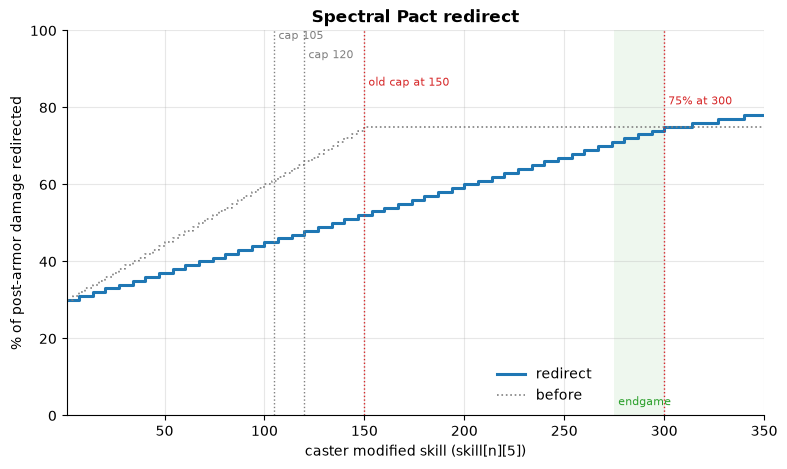

In [4]:
fig, ax = plt.subplots()
ax.step(P, redirect_pct(P), where="post", lw=2.2, label="redirect")
ax.step(P, old_redirect_pct(P), where="post", color="grey", lw=1.2, ls=":", label="before")
mm.skill_axis(ax, "% of post-armor damage redirected", "Spectral Pact redirect")
ax.set_ylim(0, 100)
mm.mark_caps(ax, extra=[(150, "old cap at 150"), (mm.SKILL_KNEE, "75% at 300")])
ax.legend(loc="lower right", bbox_to_anchor=(0.77, 0))

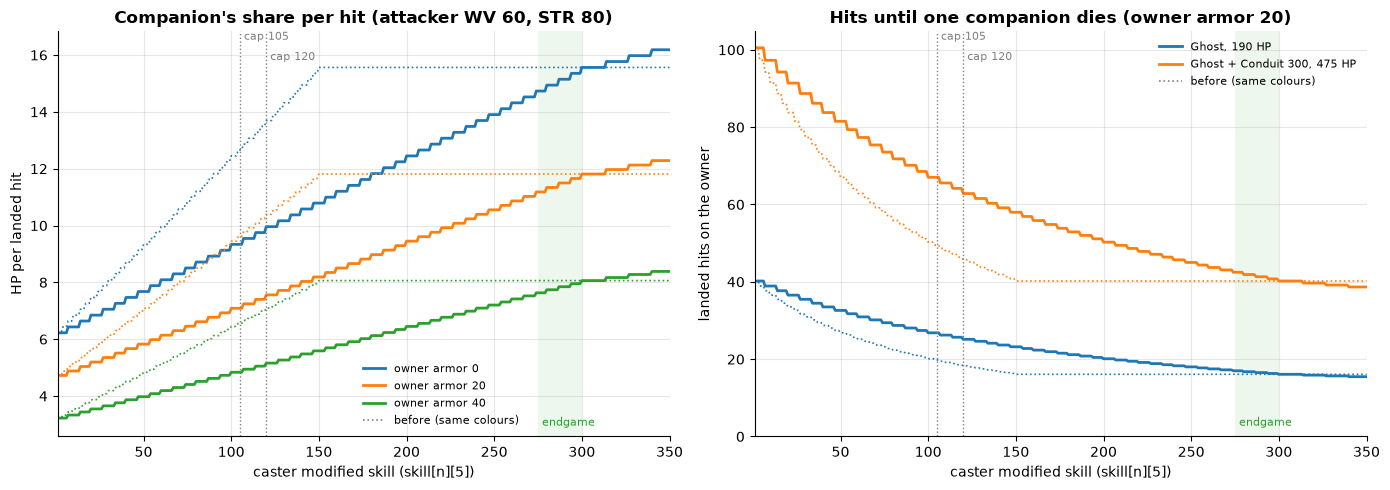

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
colors = ("tab:blue", "tab:orange", "tab:green")

ax = axes[0]
for c, owner_armor in zip(colors, (0, 20, 40)):
    ax.plot(P, melee_companion_hp(P, owner_armor), color=c, label=f"owner armor {owner_armor}")
    ax.plot(P, melee_companion_hp(P, owner_armor, redirect=old_redirect_pct), color=c, lw=1.2, ls=":")
ax.plot([], [], color="grey", lw=1.2, ls=":", label="before (same colours)")
mm.skill_axis(ax, "HP per landed hit", "Companion's share per hit (attacker WV 60, STR 80)")
mm.mark_caps(ax)
ax.legend(fontsize=8, loc="lower right", bbox_to_anchor=(0.77, 0))

ax = axes[1]
for c, hp, name in zip(colors, (190, 475), ("Ghost, 190 HP", "Ghost + Conduit 300, 475 HP")):
    ax.plot(P, companion_hits(P, hp), color=c, label=name)
    ax.plot(P, companion_hits(P, hp, redirect=old_redirect_pct), color=c, lw=1.2, ls=":")
ax.plot([], [], color="grey", lw=1.2, ls=":", label="before (same colours)")
mm.skill_axis(ax, "landed hits on the owner", "Hits until one companion dies (owner armor 20)")
ax.set_ylim(0, None)
mm.mark_caps(ax)
ax.legend(fontsize=8, loc="upper right")
plt.tight_layout()

# Observations

- The redirect reaches 75% at modified skill 300 instead of 150. At the endgame (275–300) it is
  71–75%, so an armor-20 owner hit by a WV 60, STR 80 attacker takes 4.6–3.9 of 15.75 HP per hit.
  Skill from gear keeps paying: 78% at 350 and 86% at 450.
- The mid-game is weaker. At the raise cap of 105 the pact redirects 45% (before 61%), and the
  owner takes 8.7 HP per hit instead of 6.1. The old 61% is reached at skill 207.
- The 90% limit is reached at skill 500. It keeps the owner taking at least 10% of every hit, so
  the pact can never make the owner fully immune.
- The companion is the limit. Its armor does not apply to the share, so it absorbs 7.1 HP per hit
  at skill 105 and 11.8 at 300. A Ghost with about 190 HP lasts about 27 hits at 105 and 16 at
  300. With Revenant Conduit at skill 300 (about 475 HP) it lasts about 67 and 40 hits. When the
  last companion dies the pact is removed, and a new summon costs 45 mana plus a 20 mana recast.
- The owner and companions together lose exactly what the owner would have lost alone. The share
  skips the companion's armor and Magic Shield, so a tanky companion does not help. The owner's
  own Magic Shield and armor wear see the full hit, as they would without the pact.
- With Kindred Spirit each of the two companions takes half the share, so the pair lasts twice
  as long.
- Only `do_hurt` is redirected. DoT ticks that write `a_hp` directly, such as the Lava Blast
  burn, bypass the pact. The split is in thousandths of HP, so only a hit that armor fully
  absorbs redirects nothing.
- A recast is refused while the pact is up, so there is a short gap every 180 s (20 mana per
  3 minutes).